# Chapter 6: Approximate Nearest-Neighbor Search

A full scan compares the query with every stored vector. Its cost is the number of
vectors times the size of each vector. Book section 6.4 names three levers to reduce
this volume, and this demo pulls each of them in turn:

1. **Fewer dimensions**: map the vectors into a lower-dimensional space (PCA).
2. **Fewer bits per vector**: store each vector as a compact code (scalar quantization,
   the VA-file, product quantization, LSH).
3. **Fewer vectors read**: visit only the part of the collection near the query (inverted
   file, navigable small-world graphs).

We build simplified versions of each method in a few lines of numpy, measure what it
costs in result quality, and finally combine the levers with FAISS and compare them on
the recall-throughput curve, as the ann-benchmarks project does.

**Prerequisites:** ch06-01 (distances, cosine on the unit sphere) and book section 6.4.

## Setup

In [1]:
import time

import faiss
import numpy as np
import matplotlib.pyplot as plt
from shared.data import load_glove_vectors
from shared.display import print_table, display_md

N_THREADS = faiss.omp_get_max_threads()

## The collection and the exact answer

The book's measurements use GloVe-100: word vectors with 100 dimensions, compared by
cosine. We load the 400,000 GloVe vectors of the ch05-02 word-embedding demo (the same
download, about 130 MB on first use). All vectors are normalized to unit length, so the
dot product equals the cosine, and Euclidean distance ranks exactly like the cosine.

As queries, we hold out 200 words drawn from the 50,000 most frequent ones; the index
holds all other words. Exact search over the index gives the reference answer.

In [2]:
words, vectors = load_glove_vectors()
vectors /= np.linalg.norm(vectors, axis=1, keepdims=True)

rng = np.random.default_rng(0)
query_ids = rng.choice(50_000, size=200, replace=False)   # GloVe lists words by frequency
index_ids = np.setdiff1d(np.arange(len(words)), query_ids)
Q, X = vectors[query_ids], vectors[index_ids]

exact = faiss.IndexFlatIP(X.shape[1])
exact.add(X)
_, truth = exact.search(Q, 10)

print_table(
    [[words[query_ids[i]], ", ".join(words[index_ids[j]] for j in truth[i, :6])] for i in range(6)],
    headers=["Query word", "Exact 6 nearest neighbors"],
)
display_md(f"**Index:** {len(X):,} vectors x {X.shape[1]} dimensions "
           f"= {X.nbytes / 1e6:.0f} MB of float32, read in full by every query of a full scan")

| Query word   | Exact 6 nearest neighbors                                         |
|:-------------|:------------------------------------------------------------------|
| diagnoses    | diagnosis, treatments, schizophrenia, adhd, therapies, diagnostic |
| pressler     | metzenbaum, packwood, lott, mccurdy, bricker, boren               |
| auditor      | audit, auditors, comptroller, auditing, assessor, audits          |
| disliked     | resented, loathed, distrusted, displeased, dislikes, despised     |
| violated     | violating, violate, violates, violation, violations, laws         |
| base         | bases, ground, air, military, force, near                         |

**Index:** 399,800 vectors x 100 dimensions = 160 MB of float32, read in full by every query of a full scan

The quality of an approximate method is its **recall@k** against this exact answer:

$$\text{recall@}k = \frac{\lvert \text{approximate top-}k \cap \text{exact top-}k \rvert}{k}$$

Most approximate methods are used as a first stage, followed by an exact reranking step.
Every table below therefore measures each method in two ways:

1. **Approximate top 10:** the method searches on its compact data (fewer dimensions or
   short codes) and returns its 10 best vectors. The column *Recall@10, approximate top 10*
   compares them with the exact top 10.
2. **Top 100, reranked exactly:** the method returns its 100 best vectors instead. For
   these 100 candidates only, we read the full 100-dimensional vectors, compute the exact
   scores, and keep the best 10. The column *Recall@10, top 100 reranked* compares this
   result with the exact top 10. It shows whether the good matches are among the
   candidates at all.

The reranking reads only 100 full vectors per query, 0.025 percent of the collection.

In [3]:
def recall_at_k(found, k=10):
    """Mean overlap of each row of `found` with the exact top k."""
    return float(np.mean([len(set(f[:k]) & set(t[:k])) / k for f, t in zip(found, truth)]))

def rerank(candidates, k=10):
    """Reorder each query's candidates by their exact score and keep the top k."""
    return np.array([c[np.argsort(-(X[c] @ q))[:k]] for q, c in zip(Q, candidates)])

def queries_per_second(index, k=10):
    """Throughput with one query at a time on one thread, as in ann-benchmarks."""
    faiss.omp_set_num_threads(1)
    try:
        start = time.perf_counter()
        found = np.array([index.search(Q[i:i + 1], k)[1][0] for i in range(len(Q))])
        return found, len(Q) / (time.perf_counter() - start)
    finally:
        faiss.omp_set_num_threads(N_THREADS)

_, full_scan_qps = queries_per_second(exact)
display_md(f"**Full scan:** recall@10 = 1.00 at {full_scan_qps:,.0f} queries per second")

**Full scan:** recall@10 = 1.00 at 124 queries per second

# Lever 1: Fewer Dimensions

**Principal component analysis** (PCA) finds the directions along which the data varies
most and projects every vector onto the leading ones. We compute the components on a
sample of 50,000 vectors and project all vectors and queries to $d$ dimensions. For each
query, we then run the two measurements described above:

1. Search the reduced vectors with Euclidean distance and keep the 100 nearest. The first
   10 of them give the column *Recall@10, approximate top 10*.
2. Read the full vectors of these 100 candidates, rank them by their exact cosine, and
   keep the best 10. This gives the column *Recall@10, top 100 reranked*.

*Data read* is the size of the reduced vectors compared with the full ones: the work of
step 1. *Variance kept* is the share of the data's variance that the $d$ components
capture.

In [4]:
sample = X[rng.choice(len(X), 50_000, replace=False)]
mean = sample.mean(axis=0)
_, sing, components = np.linalg.svd(sample - mean, full_matrices=False)
explained = np.cumsum(sing ** 2) / np.sum(sing ** 2)

def search_l2(queries, data, k):
    index = faiss.IndexFlatL2(data.shape[1])
    index.add(np.ascontiguousarray(data, dtype=np.float32))
    return index.search(np.ascontiguousarray(queries, dtype=np.float32), k)[1]

rows = []
for d in [80, 60, 40, 20]:
    P = components[:d].T
    cand = search_l2((Q - mean) @ P, (X - mean) @ P, 100)
    rows.append([d, f"{d / 100:.0%}", f"{explained[d - 1]:.0%}",
                 f"{recall_at_k(cand):.2f}", f"{recall_at_k(rerank(cand)):.2f}"])
print_table(rows, headers=["Dimensions", "Data read", "Variance kept",
                           "Recall@10, approximate top 10", "Recall@10, top 100 reranked"])

|   Dimensions | Data read   | Variance kept   |   Recall@10, approximate top 10 |   Recall@10, top 100 reranked |
|-------------:|:------------|:----------------|--------------------------------:|------------------------------:|
|           80 | 80%         | 90%             |                            0.81 |                          1    |
|           60 | 60%         | 75%             |                            0.62 |                          0.96 |
|           40 | 40%         | 59%             |                            0.42 |                          0.82 |
|           20 | 20%         | 40%             |                            0.2  |                          0.49 |

Read the row for 80 dimensions: searching the reduced vectors finds about 8 of the 10
exact neighbors. All 10 are among the 100 nearest reduced vectors, so reranking these
100 with the full vectors recovers every one of them. PCA alone loses some neighbors, and
more as the dimension drops, because GloVe's dimensions are not strongly correlated: 80
components keep only about 90 percent of the variance. As a first stage, however, PCA
works: with 80 or 60 dimensions, the good matches are almost always among the best 100
candidates, and an exact reranking restores them.
Dimensionality reduction is a modest lever, as the book says. It removes about 20 to 40
percent of the data here.

What about simply cutting the vector? Matryoshka embeddings are trained so that a prefix
is itself a usable embedding. GloVe is not trained that way. We compare PCA with keeping
the first $d$ components:

In [5]:
rows = []
for d in [80, 40]:
    P = components[:d].T
    pca = search_l2((Q - mean) @ P, (X - mean) @ P, 100)
    cut = search_l2(Q[:, :d], X[:, :d], 100)
    rows.append([d, f"{recall_at_k(rerank(pca)):.2f}", f"{recall_at_k(rerank(cut)):.2f}"])
print_table(rows, headers=["Dimensions", "PCA, reranked", "First d components, reranked"])

|   Dimensions |   PCA, reranked |   First d components, reranked |
|-------------:|----------------:|-------------------------------:|
|           80 |            1    |                           1    |
|           40 |            0.82 |                           0.73 |

With 80 of 100 dimensions, both work after reranking. At 40 dimensions, PCA keeps more
of the neighbors, because it chooses the directions with the most variance. Truncation
is a strong lever only for embeddings trained for it; demo ch06-04 uses the
Matryoshka-trained Qwen3 embeddings for that.

# Lever 2: Fewer Bits per Vector

## Scalar quantization

The simplest code replaces each float with a small integer. We divide the value range of
each dimension into $2^b$ intervals and store only the number of the interval. Distances
are then computed on the interval centers.

In [6]:
lo, hi = X.min(axis=0), X.max(axis=0)

def scalar_quantize(data, b):
    """Interval number of every component, with 2^b intervals per dimension."""
    width = (hi - lo) / 2 ** b
    return np.clip(((data - lo) / width).astype(np.int32), 0, 2 ** b - 1), width

rows = []
for b in [8, 4, 2]:
    codes, width = scalar_quantize(X, b)
    centers = (lo + (codes + 0.5) * width).astype(np.float32)
    cand = search_l2(Q, centers, 100)
    rows.append([b, f"{100 * b // 8} B", f"1:{32 // b}",
                 f"{recall_at_k(cand):.2f}", f"{recall_at_k(rerank(cand)):.2f}"])
print_table(rows, headers=["Bits b", "Bytes per vector", "Compression",
                           "Recall@10, approximate top 10", "Recall@10, top 100 reranked"])

|   Bits b | Bytes per vector   | Compression   |   Recall@10, approximate top 10 |   Recall@10, top 100 reranked |
|---------:|:-------------------|:--------------|--------------------------------:|------------------------------:|
|        8 | 100 B              | 1:4           |                            0.99 |                          1    |
|        4 | 50 B               | 1:8           |                            0.86 |                          1    |
|        2 | 25 B               | 1:16          |                            0.52 |                          0.93 |

With 8 bits, the codes are almost as good as the floats. With 4 bits, recall drops, but
the good matches are still among the best 100 candidates.

## The VA-file: quantization that stays exact

The **vector approximation file** uses the same codes for an exact search. The interval
numbers of a vector describe a grid cell, and the cell bounds the distance to every
vector inside it. We first reproduce the book's 2D example: $b = 2$ bits per dimension,
the vector $\mathbf{p} = (0.62, 0.10)$, and the query $\mathbf{q} = (0.20, 0.55)$.

In [7]:
def cell_bounds(q, cell_lo, cell_hi):
    """Lower and upper bound on the distance from q to any point of a grid cell."""
    lower = np.maximum(0, np.maximum(cell_lo - q, q - cell_hi))
    upper = np.maximum(np.abs(q - cell_lo), np.abs(q - cell_hi))
    return np.sqrt((lower ** 2).sum(-1)), np.sqrt((upper ** 2).sum(-1))

p, q = np.array([0.62, 0.10]), np.array([0.20, 0.55])
width = 1 / 2 ** 2
cell = (p // width).astype(int)
low, up = cell_bounds(q, cell * width, (cell + 1) * width)
display_md(
    f"| | Value |\n|---|---|\n"
    f"| Code of $\\mathbf{{p}}$ | ({cell[0]:02b}, {cell[1]:02b}) |\n"
    f"| Lower bound | {low:.2f} |\n"
    f"| Exact distance | {np.linalg.norm(p - q):.2f} |\n"
    f"| Upper bound | {up:.2f} |"
)

| | Value |
|---|---|
| Code of $\mathbf{p}$ | (10, 00) |
| Lower bound | 0.42 |
| Exact distance | 0.62 |
| Upper bound | 0.78 |

The search runs in two phases. The **filtering phase** scans all codes and discards every
vector whose lower bound exceeds the $k$-th smallest upper bound. The **refinement phase**
reads the remaining candidates in order of increasing lower bound and stops as soon as the
next lower bound exceeds the $k$-th best exact distance. We run it on GloVe for 20 queries.

In [8]:
def va_file_search(q, cell_lo, cell_hi, k=10):
    """Exact k-NN with a VA-file; returns the result and the work done."""
    lower, upper = cell_bounds(q, cell_lo, cell_hi)
    kth_upper = np.partition(upper, k - 1)[k - 1]
    candidates = np.flatnonzero(lower <= kth_upper)            # filtering phase
    best, reads = [], 0
    for i in candidates[np.argsort(lower[candidates])]:         # refinement phase
        if len(best) == k and lower[i] > best[-1][0]:
            break
        reads += 1
        best = sorted(best + [(np.linalg.norm(X[i] - q), i)])[:k]
    return [i for _, i in best], len(candidates), reads

rows = []
for b in [4, 6, 8]:
    codes, width = scalar_quantize(X, b)
    cell_lo = (lo + codes * width).astype(np.float32)
    cell_hi = cell_lo + width.astype(np.float32)
    runs = [va_file_search(Q[i], cell_lo, cell_hi) for i in range(20)]
    exact_found = np.mean([len(set(r[0]) & set(truth[i])) / 10 for i, r in enumerate(runs)])
    n_cand, n_read = np.mean([r[1] for r in runs]), np.mean([r[2] for r in runs])
    rows.append([b, f"{n_cand:,.0f}", f"{n_read:,.0f}", f"{b / 32 + n_read / len(X):.1%}",
                 f"{exact_found:.2f}"])
print_table(rows, headers=["Bits b", "Candidates after filtering", "Exact vectors read",
                           "Data read vs. full scan", "Recall@10"])

|   Bits b |   Candidates after filtering |   Exact vectors read | Data read vs. full scan   |   Recall@10 |
|---------:|-----------------------------:|---------------------:|:--------------------------|------------:|
|        4 |                       76,049 |                  813 | 12.7%                     |           1 |
|        6 |                          104 |                   30 | 18.8%                     |           1 |
|        8 |                           17 |                   13 | 25.0%                     |           1 |

The result is always exact, and every variant reads only a fraction of the data of a
full scan. The bits per dimension shift the work between the two phases. With 4 bits, the
codes are small, but the bounds are loose: tens of thousands of candidates survive the
filter, and the refinement reads hundreds of exact vectors. With 6 or 8 bits, the filter
reads more, but only a few dozen exact vectors remain. On disk, every exact vector is a
random read, which favors the longer codes. Skipping the refinement would turn the same
codes into an approximate method: scalar quantization is the bridge between exact and
approximate search.

## Product quantization

**Product quantization** (PQ) quantizes groups of dimensions together. The book splits
the eight-dimensional vector $(0.1, 0.3, 0.5, 0.2, 0.6, 0.4, 0.9, 0.8)$ into $m = 4$
sub-vectors and replaces each by the 2-bit number of its nearest center in that
sub-space's codebook. The figure does not show the codebooks, so we choose four centers
per sub-space by hand.

In [9]:
codebooks_toy = np.array([
    [[0.1, 0.2], [0.5, 0.5], [0.8, 0.2], [0.3, 0.8]],   # sub-space 1
    [[0.1, 0.1], [0.2, 0.7], [0.6, 0.2], [0.8, 0.8]],   # sub-space 2
    [[0.1, 0.2], [0.6, 0.5], [0.2, 0.8], [0.9, 0.1]],   # sub-space 3
    [[0.2, 0.2], [0.5, 0.1], [0.8, 0.9], [0.3, 0.7]],   # sub-space 4
])
v = np.array([0.1, 0.3, 0.5, 0.2, 0.6, 0.4, 0.9, 0.8])
subs = v.reshape(4, 2)
code = np.argmin(((codebooks_toy - subs[:, None, :]) ** 2).sum(-1), axis=1)

pair = lambda x: f"({x[0]:.1f}, {x[1]:.1f})"
print_table(
    [[j + 1, pair(subs[j]), f"{code[j]:02b}", pair(codebooks_toy[j, code[j]])] for j in range(4)],
    headers=["Sub-space", "Sub-vector", "Code", "Center it stands for"],
)
display_md(f"**Stored:** {4 * 2} bits instead of {8 * 32} bits, a compression of 1:{8 * 32 // 8}")

|   Sub-space | Sub-vector   |   Code | Center it stands for   |
|------------:|:-------------|-------:|:-----------------------|
|           1 | (0.1, 0.3)   |     00 | (0.1, 0.2)             |
|           2 | (0.5, 0.2)   |     10 | (0.6, 0.2)             |
|           3 | (0.6, 0.4)   |     01 | (0.6, 0.5)             |
|           4 | (0.9, 0.8)   |     10 | (0.8, 0.9)             |

**Stored:** 8 bits instead of 256 bits, a compression of 1:32

The search uses lookup tables. For a query, we compute the squared distance between each
query sub-vector and every center once. The approximate distance to a stored vector is
then a sum of $m$ table look-ups:

$$\tilde{\delta}(\mathbf{q}, \mathbf{p})^2 = \sum_{j=1}^{m} \lVert \mathbf{q}_j - \mathbf{c}_j(\mathbf{p}) \rVert^2$$

In [10]:
q_toy = np.array([0.2, 0.3, 0.4, 0.3, 0.7, 0.4, 0.8, 0.7])
tables = ((codebooks_toy - q_toy.reshape(4, 1, 2)) ** 2).sum(-1)    # m x 2^b, once per query
approx = tables[np.arange(4), code].sum()
display_md(
    f"- Lookup tables: {tables.shape[0]} x {tables.shape[1]} entries\n"
    f"- Approximate distance (4 look-ups): {np.sqrt(approx):.4f}\n"
    f"- Distance to the reconstructed vector: {np.linalg.norm(q_toy - codebooks_toy[np.arange(4), code].ravel()):.4f}\n"
    f"- Exact distance: {np.linalg.norm(q_toy - v):.4f}"
)

- Lookup tables: 4 x 4 entries
- Approximate distance (4 look-ups): 0.3606
- Distance to the reconstructed vector: 0.3606
- Exact distance: 0.2449

The look-ups give exactly the distance to the reconstructed vector. With only four
centers per sub-space, that is a coarse approximation of the exact distance. On GloVe, we use the standard choice $b = 8$, so each code is one byte and
each codebook holds 256 centers found by k-means. We try $m = 10$, $20$, and $50$
sub-vectors, of 10, 5, and 2 dimensions each.

In [11]:
def pq_train(m, b=8, seed=0):
    """One k-means codebook with 2^b centers per sub-space."""
    dsub = X.shape[1] // m
    books = []
    for j in range(m):
        km = faiss.Kmeans(dsub, 2 ** b, niter=20, seed=seed)
        km.train(np.ascontiguousarray(sample[:, j * dsub:(j + 1) * dsub]))
        books.append(km.centroids)
    return np.stack(books)

def pq_encode(data, books):
    m, _, dsub = books.shape
    codes = np.empty((len(data), m), dtype=np.uint8)
    for j in range(m):
        codes[:, j] = search_l2(data[:, j * dsub:(j + 1) * dsub], books[j], 1)[:, 0]
    return codes

def pq_search(q, codes, books, k=100):
    m, _, dsub = books.shape
    tables = ((books - q.reshape(m, 1, dsub)) ** 2).sum(-1)
    dist = tables[np.arange(m), codes].sum(axis=1)
    top = np.argpartition(dist, k)[:k]
    return top[np.argsort(dist[top])]

rows = []
for m in [10, 20, 50]:
    books = pq_train(m)
    codes = pq_encode(X, books)
    cand = np.array([pq_search(q, codes, books) for q in Q])
    rows.append([m, X.shape[1] // m, f"{m} B", f"1:{400 // m}",
                 f"{recall_at_k(cand):.2f}", f"{recall_at_k(rerank(cand)):.2f}"])
print_table(rows, headers=["Sub-vectors m", "Dimensions each", "Bytes per vector",
                           "Compression", "Recall@10, approximate top 10", "Recall@10, top 100 reranked"])

|   Sub-vectors m |   Dimensions each | Bytes per vector   | Compression   |   Recall@10, approximate top 10 |   Recall@10, top 100 reranked |
|----------------:|------------------:|:-------------------|:--------------|--------------------------------:|------------------------------:|
|              10 |                10 | 10 B               | 1:40          |                            0.43 |                          0.86 |
|              20 |                 5 | 20 B               | 1:20          |                            0.66 |                          0.98 |
|              50 |                 2 | 50 B               | 1:8           |                            0.89 |                          1    |

Short sub-vectors approximate the distance well but compress less. Long sub-vectors
compress more and lose more neighbors, which a final reranking step partly compensates.
At 20 bytes per vector, PQ compresses 1:20 and uses 1.6 bits per dimension. Scalar
quantization with 2 bits per dimension needs more bytes (25) and loses more neighbors.

## Locality-sensitive hashing

**Locality-sensitive hashing** (LSH) chooses $h$ hyperplanes and stores one bit per
hyperplane: 1 if the vector lies on its positive side. The book's figure draws three
lines in the plane and gets seven regions; the eighth code cannot occur. We draw three
random lines and count the codes that actually appear.

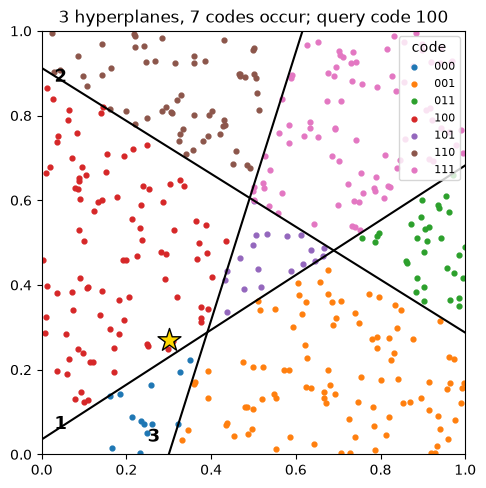

In [12]:
# Three lines placed like the book's figure: bit j is 1 if normal_j . x > offset_j.
lines = [(np.array([-0.55, 0.85]), 0.03),     # hyperplane 1, positive side above
         (np.array([0.50, 0.80]), 0.73),      # hyperplane 2, positive side above
         (np.array([0.95, -0.30]), 0.285)]    # hyperplane 3, positive side to the right
normals = np.array([n for n, _ in lines])
offsets = np.array([o for _, o in lines])

def lsh_code(x):
    return "".join(map(str, (x @ normals.T > offsets).astype(int)))

pts = np.random.default_rng(4).random((400, 2))
labels = np.array([lsh_code(x) for x in pts])
q2 = np.array([0.30, 0.27])

fig, ax = plt.subplots(figsize=(5.5, 5.5))
codes_seen = sorted(set(labels))
for c_i, c in enumerate(codes_seen):
    ax.scatter(*pts[labels == c].T, s=12, color=plt.get_cmap("tab10")(c_i), label=c)
xs = np.linspace(-0.2, 1.2, 2)
for n, o in lines:
    if abs(n[1]) > 0.5:
        ax.plot(xs, (o - n[0] * xs) / n[1], color="black", lw=1.5)
    else:
        ax.plot((o - n[1] * xs) / n[0], xs, color="black", lw=1.5)
for j, xy in enumerate([(0.03, 0.06), (0.03, 0.88), (0.25, 0.03)]):
    ax.text(*xy, str(j + 1), fontsize=13, weight="bold")
ax.scatter(*q2, marker="*", s=300, color="gold", edgecolors="black", zorder=5)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_aspect("equal")
ax.legend(title="code", fontsize=8, loc="upper right")
ax.set_title(f"3 hyperplanes, {len(codes_seen)} codes occur; query code {lsh_code(q2)}")
plt.show()

With many hyperplanes, most of the $2^h$ codes are empty, and the query's bucket is
likely empty as well. LSH therefore ranks all codes by their **Hamming distance** to the
query's code. For hyperplanes through the origin, the probability that a hyperplane
separates two vectors is $\theta / \pi$, so the expected Hamming distance is
$h \cdot \theta / \pi$. We check this on random GloVe pairs with $h = 256$.

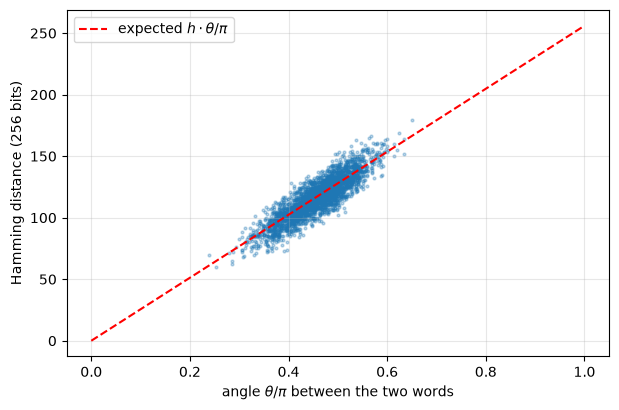

**Angle π/4, 256 bits, 2,000 random hyperplane sets:** Hamming distance 64.1 ± 6.9 (book: 64 ± 6.9)

In [13]:
h = 256
planes = rng.standard_normal((X.shape[1], h)).astype(np.float32)
i, j = rng.integers(0, len(X), 3000), rng.integers(0, len(X), 3000)
theta = np.arccos(np.clip((X[i] * X[j]).sum(axis=1), -1, 1))
hamming = ((X[i] @ planes > 0) != (X[j] @ planes > 0)).sum(axis=1)

# The book's dropdown: two vectors at an angle of pi/4, many random sets of 256 hyperplanes.
a = np.zeros(100, dtype=np.float32); a[0] = 1
b_vec = np.zeros(100, dtype=np.float32); b_vec[:2] = np.cos(np.pi / 4), np.sin(np.pi / 4)
ham_45 = np.array([((a @ P > 0) != (b_vec @ P > 0)).sum()
                   for P in (rng.standard_normal((100, h)).astype(np.float32) for _ in range(2000))])

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(theta / np.pi, hamming, s=4, alpha=0.3)
ax.plot([0, 1], [0, h], "r--", label=r"expected $h \cdot \theta / \pi$")
ax.set_xlabel(r"angle $\theta / \pi$ between the two words")
ax.set_ylabel(f"Hamming distance ({h} bits)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()
display_md(f"**Angle π/4, {h} bits, 2,000 random hyperplane sets:** Hamming distance "
           f"{ham_45.mean():.1f} ± {ham_45.std():.1f} (book: 64 ± 6.9)")

The Hamming distance tracks the angle, with a spread that only shrinks with more bits.
FAISS has a binary index that compares bit strings with an exclusive-or and a bit count.
We use it to rank all codes for each query.

In [14]:
rows = []
for h in [64, 128, 256, 512, 1024]:
    planes = rng.standard_normal((X.shape[1], h)).astype(np.float32)
    binary = faiss.IndexBinaryFlat(h)
    binary.add(np.packbits(X @ planes > 0, axis=1))
    _, cand = binary.search(np.packbits(Q @ planes > 0, axis=1), 100)
    rows.append([h, f"{h // 8} B", f"1:{400 * 8 // h}",
                 f"{recall_at_k(cand):.2f}", f"{recall_at_k(rerank(cand)):.2f}"])
print_table(rows, headers=["Bits h", "Bytes per vector", "Compression",
                           "Recall@10, approximate top 10", "Recall@10, top 100 reranked"])

|   Bits h | Bytes per vector   | Compression   |   Recall@10, approximate top 10 |   Recall@10, top 100 reranked |
|---------:|:-------------------|:--------------|--------------------------------:|------------------------------:|
|       64 | 8 B                | 1:50          |                            0.18 |                          0.43 |
|      128 | 16 B               | 1:25          |                            0.32 |                          0.69 |
|      256 | 32 B               | 1:12          |                            0.48 |                          0.88 |
|      512 | 64 B               | 1:6           |                            0.6  |                          0.97 |
|     1024 | 128 B              | 1:3           |                            0.71 |                          0.99 |

LSH finds the region of the good matches but not the order within it: words at almost
the same angle get almost the same Hamming distance. Its codes are tiny and fast to
compare, and an exact reranking of the best candidates is part of the method.

# Lever 3: Fewer Vectors Read

## Inverted file

The **inverted file** (IVF) clusters the vectors around $n_{\text{list}}$ k-means
centers and keeps one list of vectors per center. A query is compared with all centers,
and the search scans only the lists of the $n_{\text{probe}}$ nearest ones. We first look
at it in 2D, with $n_{\text{list}} = 10$.

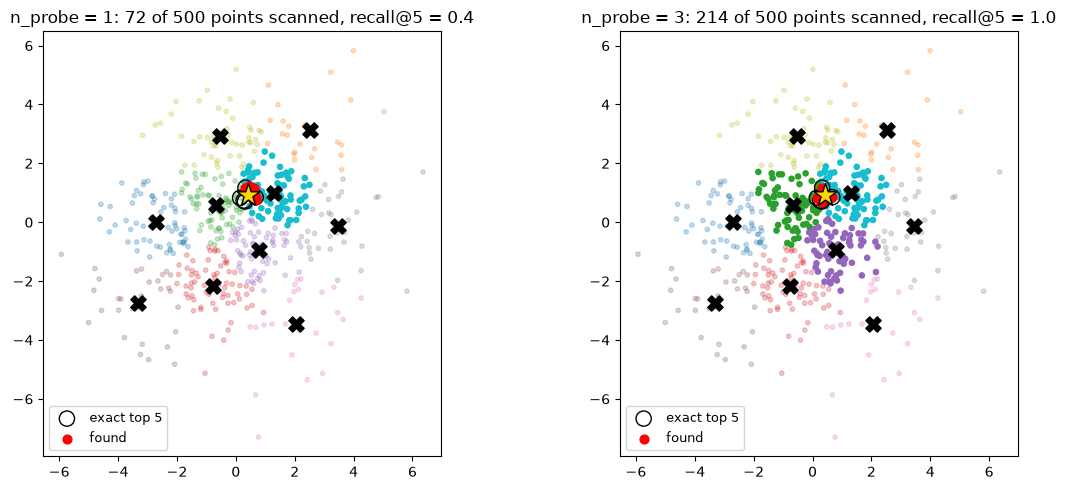

In [15]:
pts2 = (np.random.default_rng(42).standard_normal((500, 2)) * 2).astype(np.float32)
km = faiss.Kmeans(2, 10, niter=25, seed=1)
km.train(pts2)
centers2 = km.centroids
assign2 = search_l2(pts2, centers2, 1)[:, 0]

def ivf_2d(q, n_probe, k=5):
    """Scan the lists of the n_probe nearest centers; return scanned points and top k."""
    probed = np.argsort(np.linalg.norm(centers2 - q, axis=1))[:n_probe]
    scanned = np.flatnonzero(np.isin(assign2, probed))
    return scanned, set(scanned[np.argsort(np.linalg.norm(pts2[scanned] - q, axis=1))[:k]])

# Pick the first random query whose exact neighbors straddle a cluster boundary.
rng4 = np.random.default_rng(0)
while True:
    q_ivf = rng4.uniform(-2, 2, 2).astype(np.float32)
    exact5 = set(np.argsort(np.linalg.norm(pts2 - q_ivf, axis=1))[:5])
    if len(ivf_2d(q_ivf, 1)[1] & exact5) < 5 and ivf_2d(q_ivf, 3)[1] == exact5:
        break

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, n_probe in zip(axes, [1, 3]):
    scanned, found = ivf_2d(q_ivf, n_probe)
    ax.scatter(*pts2.T, s=10, c=assign2, cmap="tab10", alpha=0.25)
    ax.scatter(*pts2[scanned].T, s=14, c=assign2[scanned], cmap="tab10", vmin=0, vmax=9)
    ax.scatter(*pts2[list(exact5)].T, s=120, facecolors="none", edgecolors="black", label="exact top 5")
    ax.scatter(*pts2[list(found)].T, s=40, color="red", label="found")
    ax.scatter(*centers2.T, marker="X", s=120, color="black")
    ax.scatter(*q_ivf, marker="*", s=300, color="gold", edgecolors="black", zorder=5)
    ax.set_title(f"n_probe = {n_probe}: {len(scanned)} of 500 points scanned, "
                 f"recall@5 = {len(found & exact5) / 5:.1f}")
    ax.legend(loc="lower left", fontsize=9)
    ax.set_aspect("equal")
plt.tight_layout()
plt.show()

Neighbors just across a cluster boundary are missed unless their list is probed. On
GloVe, we use FAISS's inverted file with $n_{\text{list}} = 1024$, about 390 vectors per
list. FAISS does exactly what the 2D code does: k-means, one list per center, and a scan
of the probed lists.

In [16]:
ivf = faiss.index_factory(X.shape[1], "IVF1024,Flat", faiss.METRIC_INNER_PRODUCT)
ivf.train(X)
ivf.add(X)

rows = []
for n_probe in [1, 5, 10, 20, 50, 100]:
    ivf.nprobe = n_probe
    found, qps = queries_per_second(ivf)
    rows.append([n_probe, f"{n_probe / 1024:.1%}", f"{recall_at_k(found):.2f}", f"{qps:,.0f}"])
print_table(rows, headers=["Probed lists", "Share read", "Recall@10", "Queries per second"])

|   Probed lists | Share read   |   Recall@10 |   Queries per second |
|---------------:|:-------------|------------:|---------------------:|
|              1 | 0.1%         |        0.53 |               53,766 |
|              5 | 0.5%         |        0.8  |               21,588 |
|             10 | 1.0%         |        0.88 |               14,886 |
|             20 | 2.0%         |        0.93 |                7,792 |
|             50 | 4.9%         |        0.97 |                3,244 |
|            100 | 9.8%         |        0.99 |                1,587 |

The pattern is the one of the book's ann-benchmarks table on the full 1.2 million GloVe
vectors (0.84 at 1.2 percent read, 0.93 at 4.9 percent). Recall is somewhat higher here,
because our collection is smaller and our queries are frequent words. The cost grows
linearly with the probed lists, while the gain in recall shrinks: the last points of
recall are the most expensive.

## Navigable small-world graphs

A **navigable small-world** (NSW) graph links every vector to a few of its nearest
neighbors. We build one in 2D the way NSW does: insert the points in random order and
link each new point to its $M = 3$ nearest points inserted so far. Early points get links
across the whole space, which later act as shortcuts.

In [17]:
def build_nsw(points, M=3, seed=0):
    order = np.random.default_rng(seed).permutation(len(points))
    graph = {int(i): set() for i in order}
    for t, i in enumerate(order[1:], start=1):
        earlier = order[:t]
        nearest = earlier[np.argsort(np.linalg.norm(points[earlier] - points[i], axis=1))[:M]]
        for j in nearest:
            graph[int(i)].add(int(j))
            graph[int(j)].add(int(i))
    return graph, int(order[0])

def nsw_search(q, points, graph, entry, ef=1):
    """Best-first search that keeps the ef closest nodes found; ef = 1 is greedy search."""
    dist = lambda i: float(np.linalg.norm(points[i] - q))
    visited, path = {entry}, []
    candidates, best = [(dist(entry), entry)], [(dist(entry), entry)]
    while candidates:
        candidates.sort()
        d_c, c = candidates.pop(0)
        if d_c > best[-1][0]:
            break                       # no candidate can improve the result
        path.append(c)
        for nb in graph[c]:
            if nb not in visited:
                visited.add(nb)
                d_nb = dist(nb)
                if len(best) < ef or d_nb < best[-1][0]:
                    candidates.append((d_nb, nb))
                    best = sorted(best + [(d_nb, nb)])[:ef]
    return best[0][1], path, len(visited)

nodes = np.random.default_rng(7).random((300, 2))
graph, entry = build_nsw(nodes)

Greedy search moves to whichever neighbor is closest to the query and stops when no
neighbor is closer. That node is a local minimum, not necessarily the nearest neighbor.
We look for a query where this happens and run the search again with a candidate list of
length $ef_{\text{search}} = 8$.

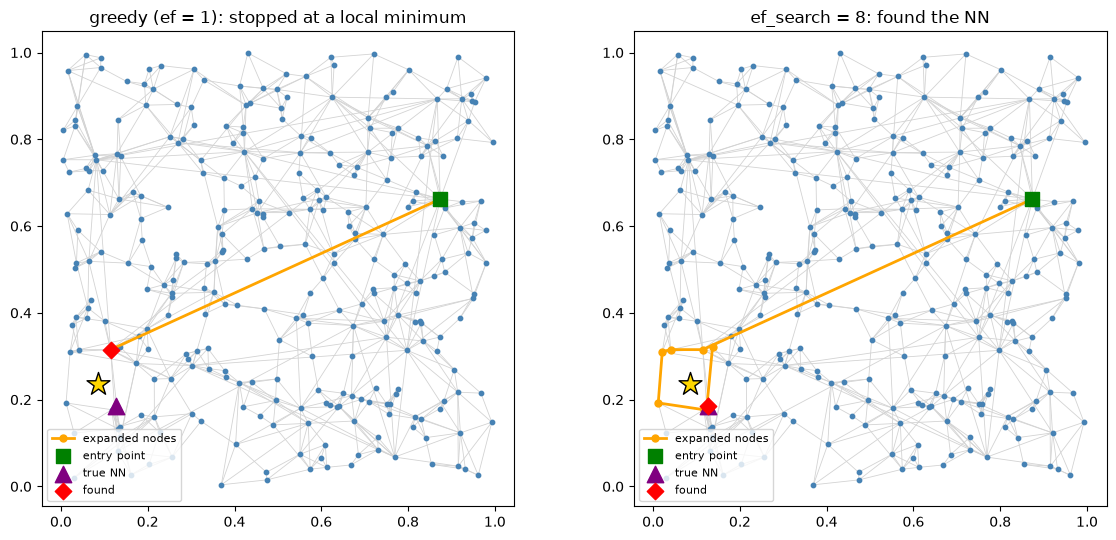

In [18]:
rng3 = np.random.default_rng(3)
while True:
    q_g = rng3.random(2)
    true_nn = int(np.argmin(np.linalg.norm(nodes - q_g, axis=1)))
    found_greedy, path_greedy, _ = nsw_search(q_g, nodes, graph, entry, ef=1)
    if found_greedy != true_nn:
        break
found_ef, path_ef, _ = nsw_search(q_g, nodes, graph, entry, ef=8)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, (title, found, path) in zip(axes, [("greedy (ef = 1)", found_greedy, path_greedy),
                                           ("ef_search = 8", found_ef, path_ef)]):
    for i, nbs in graph.items():
        for j in nbs:
            if i < j:
                ax.plot(*nodes[[i, j]].T, color="lightgray", lw=0.6, zorder=1)
    ax.scatter(*nodes.T, s=10, color="steelblue", zorder=2)
    ax.plot(*nodes[path].T, "o-", color="orange", lw=2, ms=5, zorder=3, label="expanded nodes")
    ax.scatter(*nodes[entry], marker="s", s=100, color="green", zorder=4, label="entry point")
    ax.scatter(*nodes[true_nn], marker="^", s=140, color="purple", zorder=4, label="true NN")
    ax.scatter(*nodes[found], marker="D", s=70, color="red", zorder=5, label="found")
    ax.scatter(*q_g, marker="*", s=300, color="gold", edgecolors="black", zorder=6)
    ax.set_title(f"{title}: {'found the NN' if found == true_nn else 'stopped at a local minimum'}")
    ax.set_aspect("equal")
    ax.legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

How often does this happen? We run 1,000 random queries for several values of
$ef_{\text{search}}$ and count the distance computations.

In [19]:
qs = np.random.default_rng(11).random((1000, 2))
truth_2d = np.argmin(np.linalg.norm(nodes[None] - qs[:, None], axis=2), axis=1)
rows = []
for ef in [1, 2, 4, 8, 16]:
    res = [nsw_search(q, nodes, graph, entry, ef) for q in qs]
    hit = np.mean([r[0] == t for r, t in zip(res, truth_2d)])
    rows.append([ef, f"{hit:.1%}", f"{np.mean([r[2] for r in res]):.0f}"])
print_table(rows, headers=["ef_search", "Queries that find the true NN", "Distance computations (of 300)"])

|   ef_search | Queries that find the true NN   |   Distance computations (of 300) |
|------------:|:--------------------------------|---------------------------------:|
|           1 | 89.8%                           |                               35 |
|           2 | 94.5%                           |                               36 |
|           4 | 97.8%                           |                               38 |
|           8 | 99.5%                           |                               43 |
|          16 | 99.8%                           |                               51 |

A longer candidate list costs more steps and finds the nearest neighbor more often.
**HNSW** stacks several such graphs: each higher layer holds a random subset of the layer
below, so the search covers long distances at the top and refines on the base layer. We
build FAISS's HNSW with $M = 32$ on GloVe.

In [20]:
hnsw = faiss.IndexHNSWFlat(X.shape[1], 32, faiss.METRIC_INNER_PRODUCT)
start = time.perf_counter()
hnsw.add(X)
build_s = time.perf_counter() - start

levels = faiss.vector_to_array(hnsw.hnsw.levels)
links = faiss.vector_to_array(hnsw.hnsw.neighbors).size
display_md(
    f"**Build:** {build_s:.0f} s on {N_THREADS} threads  \n"
    f"**Nodes per layer:** " + ", ".join(f"layer {L}: {(levels > L).sum():,}" for L in range(levels.max())) + "  \n"
    f"**Links:** {links * 4 / len(X):.0f} bytes per vector on top of the {X.shape[1] * 4} bytes of the vector itself"
)

**Build:** 4 s on 24 threads  
**Nodes per layer:** layer 0: 399,800, layer 1: 12,476, layer 2: 386, layer 3: 16, layer 4: 1  
**Links:** 260 bytes per vector on top of the 400 bytes of the vector itself

In [21]:
rows = []
for ef in [16, 32, 64, 128, 256]:
    hnsw.hnsw.efSearch = ef
    found, qps = queries_per_second(hnsw)
    rows.append([ef, f"{recall_at_k(found):.2f}", f"{qps:,.0f}"])
print_table(rows, headers=["ef_search", "Recall@10", "Queries per second"])

|   ef_search |   Recall@10 |   Queries per second |
|------------:|------------:|---------------------:|
|          16 |        0.92 |               23,318 |
|          32 |        0.96 |               16,585 |
|          64 |        0.98 |                9,745 |
|         128 |        0.98 |                4,970 |
|         256 |        0.99 |                2,557 |

The speed has a price: the links add memory, every vector must stay in main memory for
the random jumps of the graph walk, and the graph takes longer to build than the
inverted file.

# Combining the Levers

FAISS names an index by its stages: an optional vector transformer (PCA), a coarse
quantizer (IVF or HNSW), a fine quantizer (PQ), and an optional refiner (`RFlat`, exact
reranking of the best $k'$ candidates). We build five configurations, sweep each one's
tuning knob, and measure recall and single-thread throughput for every setting.

In [22]:
CONFIGS = {
    "IVF1024,Flat":             ("nprobe", [1, 2, 5, 10, 20, 50, 100]),
    "HNSW32":                   ("efSearch", [16, 32, 64, 128, 256]),
    "IVF1024,PQ20,RFlat":       ("nprobe", [2, 5, 10, 20, 50]),
    "PCA80,IVF1024,PQ20,RFlat": ("nprobe", [2, 5, 10, 20, 50]),
}
BYTES = {"IVF1024,Flat": 400, "HNSW32": 400 + 256, "IVF1024,PQ20,RFlat": 20,
         "PCA80,IVF1024,PQ20,RFlat": 20}

curves = {"Flat (full scan)": [(1.0, full_scan_qps, "")]}
for name, (knob, values) in CONFIGS.items():
    index = faiss.index_factory(X.shape[1], name)      # L2 on unit vectors ranks like cosine
    index.train(X)
    index.add(X)
    params = faiss.ParameterSpace()
    curves[name] = []
    for v in values:
        params.set_index_parameter(index, knob, v)
        if "RFlat" in name:
            params.set_index_parameter(index, "k_factor_rf", 10)    # rerank the best 100
        found, qps = queries_per_second(index)
        curves[name].append((recall_at_k(found), qps, f"{knob}={v}"))
display_md("**Built and measured:** " + ", ".join(f"`{n}`" for n in CONFIGS))

**Built and measured:** `IVF1024,Flat`, `HNSW32`, `IVF1024,PQ20,RFlat`, `PCA80,IVF1024,PQ20,RFlat`

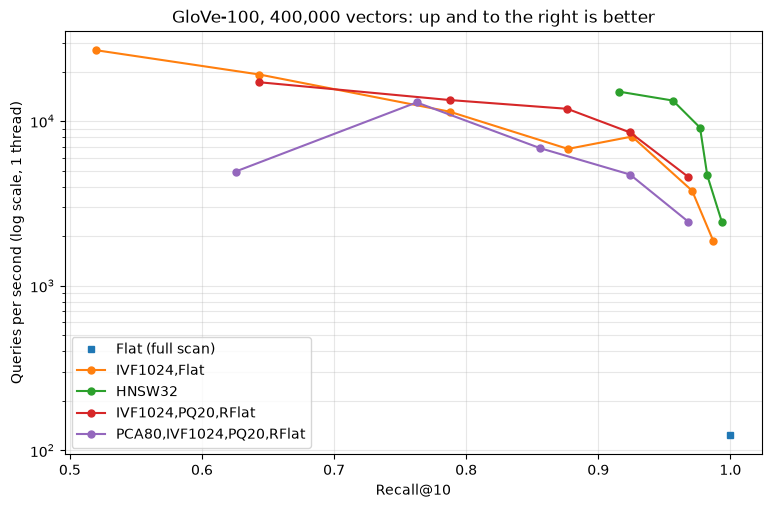

In [23]:
fig, ax = plt.subplots(figsize=(9, 5.5))
for name, pts_c in curves.items():
    r, s, _ = zip(*pts_c)
    ax.plot(r, s, "o-" if len(pts_c) > 1 else "s", label=name, ms=5)
ax.set_yscale("log")
ax.set_xlabel("Recall@10")
ax.set_ylabel("Queries per second (log scale, 1 thread)")
ax.set_title("GloVe-100, 400,000 vectors: up and to the right is better")
ax.grid(alpha=0.3, which="both")
ax.legend()
plt.show()

As in the book's ann-benchmarks figure, we read the plot by fixing the recall we need and
picking the method with the highest throughput at that recall.

In [24]:
rows = []
for target in [0.80, 0.90, 0.95]:
    best = max(((s, name, label) for name, pts_c in curves.items()
                for r, s, label in pts_c if r >= target), default=None)
    rows.append([f"{target:.2f}", f"{best[1]} ({best[2]})", f"{best[0]:,.0f}",
                 f"{best[0] / full_scan_qps:,.0f}x", f"{BYTES.get(best[1], 400)} B"])
print_table(rows, headers=["Recall@10 at least", "Fastest configuration", "Queries per second",
                           "Speed-up over full scan", "Memory per vector"])

|   Recall@10 at least | Fastest configuration   |   Queries per second | Speed-up over full scan   | Memory per vector   |
|---------------------:|:------------------------|---------------------:|:--------------------------|:--------------------|
|                 0.8  | HNSW32 (efSearch=16)    |               15,100 | 122x                      | 656 B               |
|                 0.9  | HNSW32 (efSearch=16)    |               15,100 | 122x                      | 656 B               |
|                 0.95 | HNSW32 (efSearch=32)    |               13,319 | 108x                      | 656 B               |

<div style="border-left: 4px solid #C8102E; background: rgba(200, 16, 46, 0.06); padding: 0.6em 0.9em; margin: 0.6em 0; border-radius: 4px;">
<strong style="color:#C8102E; text-transform:uppercase; font-size:0.78em; letter-spacing:0.06em;">Two orders of magnitude for a few points of recall</strong><br>
On 400,000 GloVe vectors, approximate search answers a query about two orders of magnitude faster than the full scan at a recall of 0.9 to 0.95 (see the table above). The last points of recall are the most expensive. The gain grows with the collection: the book's table for 1.2 million vectors shows two to three orders of magnitude. Speed is not the only axis: the PQ configurations need 20 bytes per vector instead of 400 to 656, which decides what fits into memory for a billion vectors.
</div>

## Summary

| Lever | Method | Knob | What we saw on GloVe-100 |
|---|---|---|---|
| Fewer dimensions | PCA | target dimension | Modest: 80 of 100 dimensions suffice as a first stage with reranking |
| Fewer bits | Scalar quantization | $b$ | 8 bits are nearly lossless; 4 bits need reranking |
| Fewer bits | VA-file | $b$ | Exact result while reading a fraction of the data |
| Fewer bits | Product quantization | $m$, $b$ | 1:20 compression; reranking repairs most losses |
| Fewer bits | LSH | $h$ | Tiny codes that track the angle; order within a cluster is noisy |
| Fewer vectors | IVF | $n_{\text{list}}$, $n_{\text{probe}}$ | Recall rises quickly, then each point costs more |
| Fewer vectors | HNSW | $M$, $ef_{\text{search}}$ | Fastest at high recall; needs links and all vectors in memory |

No single method wins on every axis. The operating point depends on the recall target,
the collection size, and the memory budget. Demo ch06-04 goes one step further: it asks
whether recall against exact search is even the right measure once a reranker reorders
the candidates.

## Try it yourself

**1. Another number of lists.** Fewer, larger lists need fewer probes for the same recall
but cost more per probe. Rebuild the inverted file with a different $n_{\text{list}}$:

In [25]:
def ivf_sweep(n_list, probes=(1, 5, 10, 20, 50)):
    index = faiss.index_factory(X.shape[1], f"IVF{n_list},Flat", faiss.METRIC_INNER_PRODUCT)
    index.train(X)
    index.add(X)
    rows = []
    for n_probe in probes:
        index.nprobe = n_probe
        found, qps = queries_per_second(index)
        rows.append([n_probe, f"{n_probe / n_list:.1%}", f"{recall_at_k(found):.2f}", f"{qps:,.0f}"])
    print_table(rows, headers=["Probed lists", "Share read", "Recall@10", "Queries per second"])

ivf_sweep(256)

|   Probed lists | Share read   |   Recall@10 |   Queries per second |
|---------------:|:-------------|------------:|---------------------:|
|              1 | 0.4%         |        0.56 |               21,798 |
|              5 | 2.0%         |        0.86 |                5,042 |
|             10 | 3.9%         |        0.93 |                2,589 |
|             20 | 7.8%         |        0.97 |                1,089 |
|             50 | 19.5%        |        0.99 |                  403 |

**2. A denser graph.** Rerun the 2D NSW experiment with `build_nsw(nodes, M=6)`. Does
greedy search reach the true nearest neighbor more often, and how many more distance
computations does it need?

**3. Your own pipeline.** Try other FAISS index strings, for example `"IVF1024,PQ50,RFlat"`
(longer codes), `"IVF1024,SQ8"` (8-bit scalar quantization), or `"IVF4096,Flat"`, and add
them to `CONFIGS`. Where do they land on the recall-throughput plot?